#Data PreProcessing



In [ ]:
import yfinance as yf

ticker = yf.Ticker("BBRI.JK")
df = ticker.history(start="2019-01-01", end="2025-12-31")
df[['Open','High','Low','Close']].to_csv("BBRI_2019_2025.csv")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM

In [ ]:
data_saham = pd.read_csv('/content/BBRI_2019_2025.csv', parse_dates=['Date'], sep=',', index_col='Date')


In [ ]:
data_saham

,Open,High,Low,Close
Date,,,,
2019-01-01 00:00:00+07:00,2286.933594,2286.933594,2286.933594,2286.933594
2019-01-02 00:00:00+07:00,2255.691406,2274.436737,2243.194575,2255.691406
2019-01-03 00:00:00+07:00,2236.946110,2274.436773,2236.946110,2261.939941
2019-01-04 00:00:00+07:00,2261.939765,2286.933594,2255.691266,2286.933594
2019-01-07 00:00:00+07:00,2311.927423,2318.175754,2286.933594,2286.933594
...,...,...,...,...
2025-12-22 00:00:00+07:00,3633.362420,3642.999986,3614.087287,3623.724854
2025-12-23 00:00:00+07:00,3623.724982,3643.000115,3594.812283,3633.362549
2025-12-24 00:00:00+07:00,3633.362549,3652.637682,3614.087416,3633.362549


Text(0.5, 1.0, 'Harga Buka Saham BBRI')

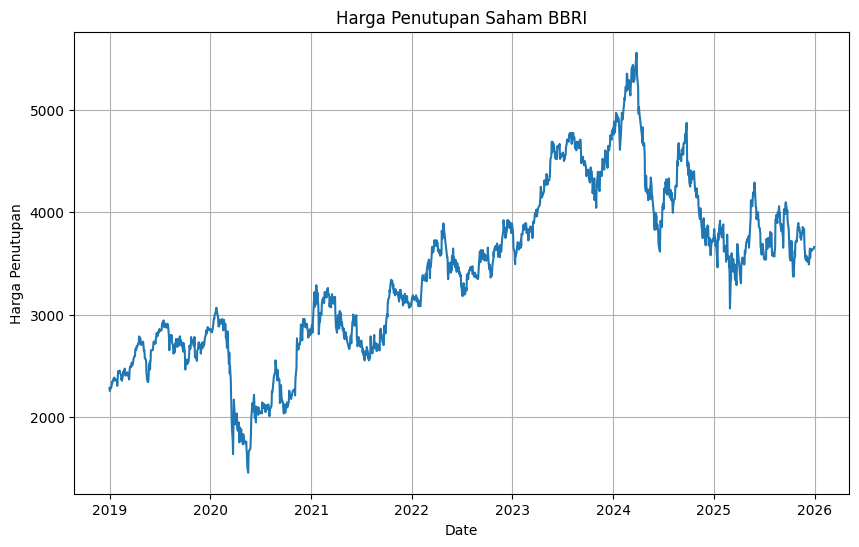

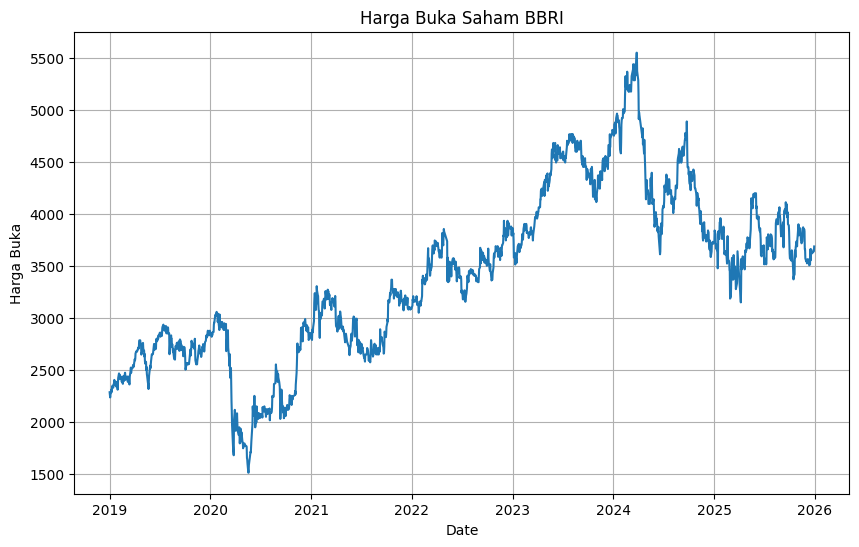

In [ ]:
#Satu Fitur
df_close = data_saham['Close']
df_open = data_saham['Open']
df_high = data_saham['High']
df_low = data_saham['Low']

#Dua Fitur
df_open_close = data_saham[['Open','Close']]
df_high_close = data_saham[['High','Close']]
df_low_close = data_saham[['Low','Close']]
df_open_high = data_saham[['Open','High']]
df_open_low = data_saham[['Open','Low']]
df_high_low = data_saham[['High','Low']]

#Tiga Fitur
df_open_high_close = data_saham[['Open','High','Close']]
df_open_low_close = data_saham[['Open','Low','Close']]
df_high_low_close = data_saham[['High','Low','Close']]
df_open_high_low = data_saham[['Open','High','Low']]

#Empat Fitur
df_open_high_low_close = data_saham[['Open','High','Low','Close']]

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_close)
plt.xlabel('Date')
plt.ylabel('Harga Penutupan')
plt.title('Harga Penutupan Saham BBRI')

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_open)
plt.xlabel('Date')
plt.ylabel('Harga Buka')
plt.title('Harga Buka Saham BBRI')

In [ ]:
df_close

,Close
Date,
2019-01-01 00:00:00+07:00,2286.933594
2019-01-02 00:00:00+07:00,2255.691406
2019-01-03 00:00:00+07:00,2261.939941
2019-01-04 00:00:00+07:00,2286.933594
2019-01-07 00:00:00+07:00,2286.933594
...,...
2025-12-22 00:00:00+07:00,3623.724854
2025-12-23 00:00:00+07:00,3633.362549
2025-12-24 00:00:00+07:00,3633.362549


<Figure size 640x480 with 0 Axes>

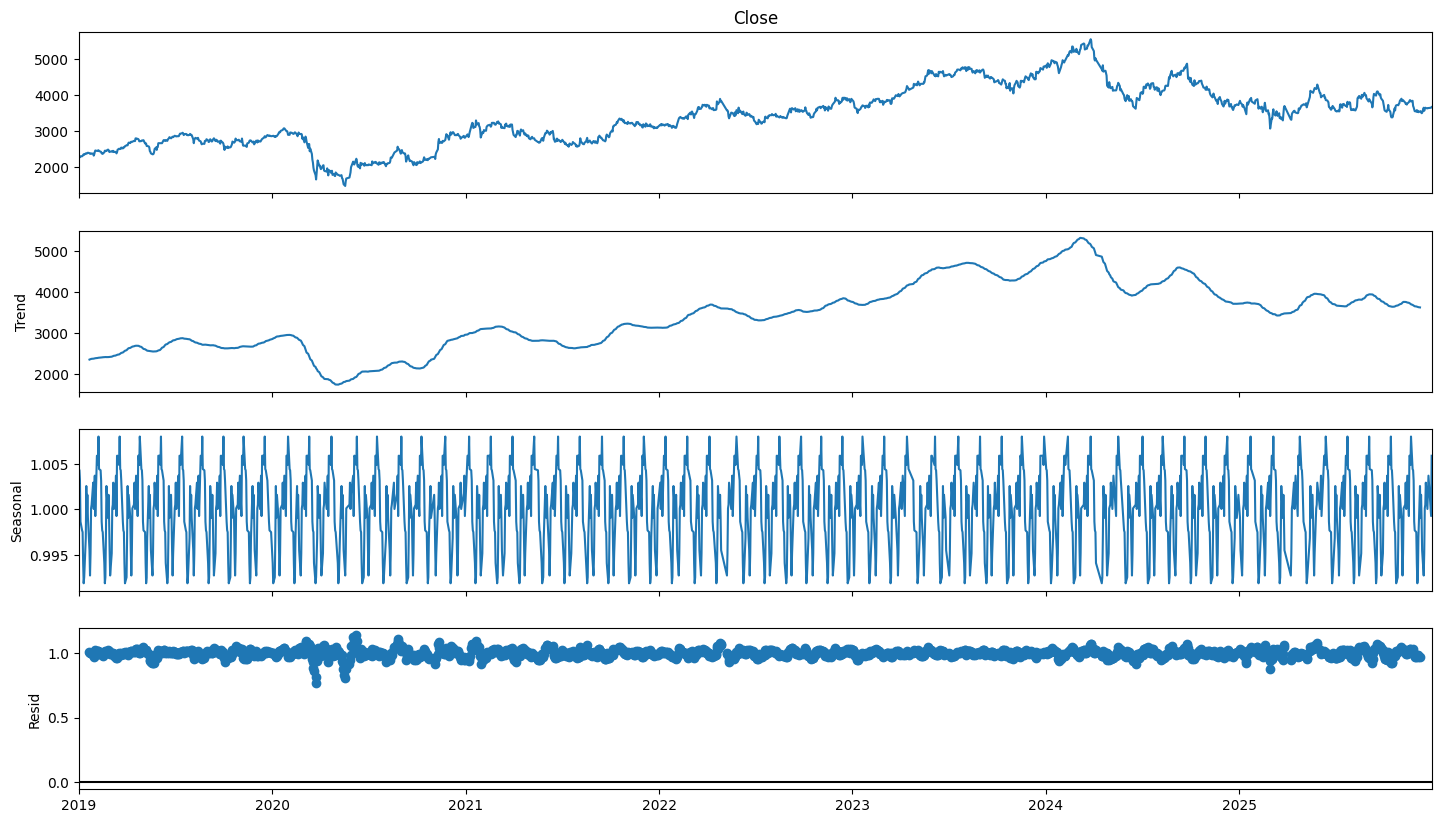

In [ ]:
result = seasonal_decompose(df_close, model='multiplicative',period=28)
fig = plt.figure()
fig = result.plot()
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

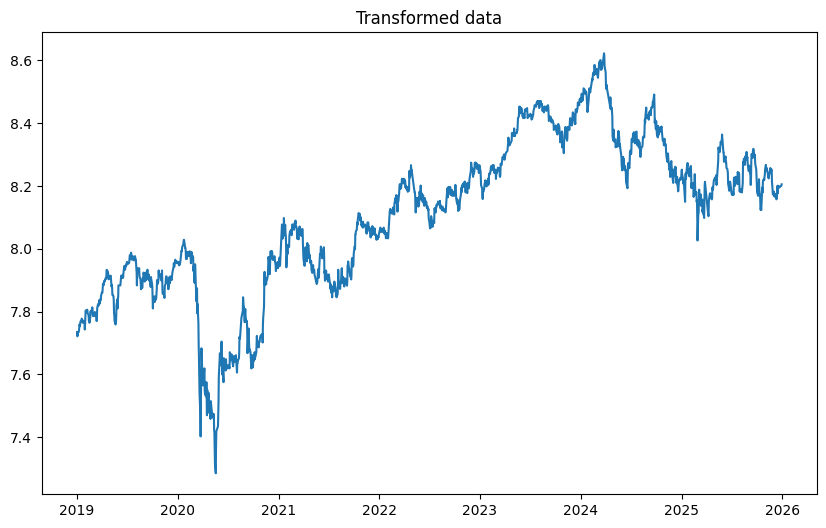

In [ ]:
#Untuk mengecilkan skala menggunakan fungsi Log tapi masih mempertahankan karakter data
df_close_log = np.log(df_close)
df_open_log = np.log(df_open)
df_high_log = np.log(df_high)
df_low_log = np.log(df_low)
df_open_close_log = np.log(df_open_close)
df_high_close_log = np.log(df_high_close)
df_low_close_log = np.log(df_low_close)
df_open_high_log = np.log(df_open_high)
df_open_low_log = np.log(df_open_low)
df_high_low_log = np.log(df_high_low)
df_open_high_close_log = np.log(df_open_high_close)
df_open_low_close_log = np.log(df_open_low_close)
df_high_low_close_log = np.log(df_high_low_close)
df_open_high_low_log = np.log(df_open_high_low)
df_open_high_low_close_log = np.log(df_open_high_low_close)

plt.figure(figsize = (10,6))
plt.plot(df_close_log)
plt.title('Transformed data')

In [ ]:
df = df_open[0:30]

In [ ]:
df

,Open
Date,
2019-01-01 00:00:00+07:00,2286.933594
2019-01-02 00:00:00+07:00,2255.691406
2019-01-03 00:00:00+07:00,2236.946110
2019-01-04 00:00:00+07:00,2261.939765
2019-01-07 00:00:00+07:00,2311.927423
2019-01-08 00:00:00+07:00,2286.933589
2019-01-09 00:00:00+07:00,2318.176304
2019-01-10 00:00:00+07:00,2336.921422
2019-01-11 00:00:00+07:00,2349.418428


In [ ]:
df.shape

(30,)

In [ ]:
df_open[1:30]

,Open
Date,
2019-01-02 00:00:00+07:00,2255.691406
2019-01-03 00:00:00+07:00,2236.946110
2019-01-04 00:00:00+07:00,2261.939765
2019-01-07 00:00:00+07:00,2311.927423
2019-01-08 00:00:00+07:00,2286.933589
2019-01-09 00:00:00+07:00,2318.176304
2019-01-10 00:00:00+07:00,2336.921422
2019-01-11 00:00:00+07:00,2349.418428
2019-01-14 00:00:00+07:00,2330.673152


In [ ]:
from sklearn.model_selection import train_test_split

# Mengumpulkan semua dataset
datasets = {
    "open": df_open_log,
    "high": df_high_log,
    "low": df_low_log,
    "close": df_close_log,

    "open_close": df_open_close_log,
    "open_high": df_open_high_log,
    "open_low": df_open_low_log,
    "high_low": df_high_low_log,
    "low_close": df_low_close_log,
    "high_close": df_high_close_log,

    "open_high_low": df_open_high_low_log,
    "open_low_close": df_open_low_close_log,
    "open_high_close": df_open_high_close_log,
    "high_low_close": df_high_low_close_log,

    "open_high_low_close": df_open_high_low_close_log
}

splits = {}

for name, df in datasets.items():

    # split train dan sementara (val+test)
    train, temp = train_test_split(df, test_size=0.30, shuffle=False)

    # split validation dan test
    val, test = train_test_split(temp, test_size=0.50, shuffle=False)

    splits[name] = {
        "train": train,
        "validation": val,
        "test": test
    }

# Satu fitur
train_open = splits["open"]["train"]
val_open = splits["open"]["validation"]
test_open = splits["open"]["test"]

train_high = splits["high"]["train"]
val_high = splits["high"]["validation"]
test_high = splits["high"]["test"]

train_low = splits["low"]["train"]
val_low = splits["low"]["validation"]
test_low = splits["low"]["test"]

train_close = splits["close"]["train"]
val_close = splits["close"]["validation"]
test_close = splits["close"]["test"]

# Dua Fitur
train_open_close = splits["open_close"]["train"]
val_open_close = splits["open_close"]["validation"]
test_open_close = splits["open_close"]["test"]

train_open_high = splits["open_high"]["train"]
val_open_high = splits["open_high"]["validation"]
test_open_high = splits["open_high"]["test"]

train_open_low = splits["open_low"]["train"]
val_open_low = splits["open_low"]["validation"]
test_open_low = splits["open_low"]["test"]

train_high_low = splits["high_low"]["train"]
val_high_low = splits["high_low"]["validation"]
test_high_low = splits["high_low"]["test"]

train_high_close = splits["high_close"]["train"]
val_high_close = splits["high_close"]["validation"]
test_high_close = splits["high_close"]["test"]

train_low_close = splits["low_close"]["train"]
val_low_close = splits["low_close"]["validation"]
test_low_close = splits["low_close"]["test"]

# Tiga fitur
train_open_high_low = splits["open_high_low"]["train"]
val_open_high_low = splits["open_high_low"]["validation"]
test_open_high_low = splits["open_high_low"]["test"]

train_open_high_close = splits["open_high_close"]["train"]
val_open_high_close = splits["open_high_close"]["validation"]
test_open_high_close = splits["open_high_close"]["test"]

train_open_low_close = splits["open_low_close"]["train"]
val_open_low_close = splits["open_low_close"]["validation"]
test_open_low_close = splits["open_low_close"]["test"]

train_high_low_close = splits["high_low_close"]["train"]
val_high_low_close = splits["high_low_close"]["validation"]
test_high_low_close = splits["high_low_close"]["test"]

# Empat Fitur
train_open_high_low_close = splits["open_high_low_close"]["train"]
val_open_high_low_close = splits["open_high_low_close"]["validation"]
test_open_high_low_close = splits["open_high_low_close"]["test"]

In [ ]:
train_open

,Open
Date,
2019-01-01 00:00:00+07:00,7.734967
2019-01-02 00:00:00+07:00,7.721212
2019-01-03 00:00:00+07:00,7.712867
2019-01-04 00:00:00+07:00,7.723978
2019-01-07 00:00:00+07:00,7.745837
...,...
2023-10-27 00:00:00+07:00,8.328961
2023-10-30 00:00:00+07:00,8.335004
2023-10-31 00:00:00+07:00,8.335004


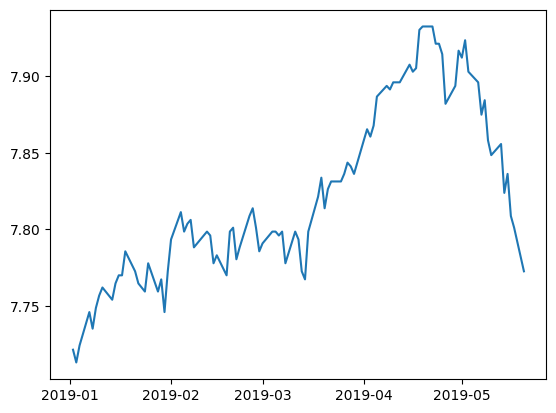

In [ ]:
plt.plot(train_open[1:100])

In [ ]:
val_open

,Open
Date,
2023-11-03 00:00:00+07:00,8.343999
2023-11-06 00:00:00+07:00,8.358814
2023-11-07 00:00:00+07:00,8.383028
2023-11-08 00:00:00+07:00,8.378232
2023-11-09 00:00:00+07:00,8.383028
...,...
2024-11-21 00:00:00+07:00,8.235718
2024-11-22 00:00:00+07:00,8.228684
2024-11-25 00:00:00+07:00,8.267904


In [ ]:
test_open

,Open
Date,
2024-11-29 00:00:00+07:00,8.235718
2024-12-02 00:00:00+07:00,8.233378
2024-12-03 00:00:00+07:00,8.226328
2024-12-04 00:00:00+07:00,8.226328
2024-12-05 00:00:00+07:00,8.242703
...,...
2025-12-22 00:00:00+07:00,8.197914
2025-12-23 00:00:00+07:00,8.195258
2025-12-24 00:00:00+07:00,8.197914


In [ ]:
train_open_close

,Open,Close
Date,,
2019-01-01 00:00:00+07:00,7.734967,7.734967
2019-01-02 00:00:00+07:00,7.721212,7.721212
2019-01-03 00:00:00+07:00,7.712867,7.723978
2019-01-04 00:00:00+07:00,7.723978,7.734967
2019-01-07 00:00:00+07:00,7.745837,7.734967
...,...,...
2023-10-27 00:00:00+07:00,8.328961,8.339012
2023-10-30 00:00:00+07:00,8.335004,8.339012
2023-10-31 00:00:00+07:00,8.335004,8.330979


In [ ]:
# Standarisasi data MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaled_splits = {}

for name, data in splits.items():

    train = data["train"]
    val = data["validation"]
    test = data["test"]

    scaler = MinMaxScaler()

    # Ensure the input to scaler is 2-dimensional
    # If it's a pandas Series, convert it to a DataFrame with a single column
    if isinstance(train, pd.Series):
        train = train.to_frame()
        val = val.to_frame()
        test = test.to_frame()

    # fit hanya pada train
    scaler.fit(train)

    # transform
    train_scaled = scaler.transform(train)
    val_scaled = scaler.transform(val)
    test_scaled = scaler.transform(test)

    scaled_splits[name] = {
        "train": train_scaled,
        "validation": val_scaled,
        "test": test_scaled,
        "scaler": scaler
    }

# Satu fitur
train_scaled_open = scaled_splits["open"]["train"]
val_scaled_open = scaled_splits["open"]["validation"]
test_scaled_open = scaled_splits["open"]["test"]

train_scaled_high = scaled_splits["high"]["train"]
val_scaled_high = scaled_splits["high"]["validation"]
test_scaled_high = scaled_splits["high"]["test"]

train_scaled_low = scaled_splits["low"]["train"]
val_scaled_low = scaled_splits["low"]["validation"]
test_scaled_low = scaled_splits["low"]["test"]

train_scaled_close = scaled_splits["close"]["train"]
val_scaled_close = scaled_splits["close"]["validation"]
test_scaled_close = scaled_splits["close"]["test"]

# Dua Fitur
train_scaled_open_close = scaled_splits["open_close"]["train"]
val_scaled_open_close = scaled_splits["open_close"]["validation"]
test_scaled_open_close = scaled_splits["open_close"]["test"]

train_scaled_open_high = scaled_splits["open_high"]["train"]
val_scaled_open_high = scaled_splits["open_high"]["validation"]
test_scaled_open_high = scaled_splits["open_high"]["test"]

train_scaled_open_low = scaled_splits["open_low"]["train"]
val_scaled_open_low = scaled_splits["open_low"]["validation"]
test_scaled_open_low = scaled_splits["open_low"]["test"]

train_scaled_high_low = scaled_splits["high_low"]["train"]
val_scaled_high_low = scaled_splits["high_low"]["validation"]
test_scaled_high_low = scaled_splits["high_low"]["test"]

train_scaled_high_close = scaled_splits["high_close"]["train"]
val_scaled_high_close = scaled_splits["high_close"]["validation"]
test_scaled_high_close = scaled_splits["high_close"]["test"]

train_scaled_low_close = scaled_splits["low_close"]["train"]
val_scaled_low_close = scaled_splits["low_close"]["validation"]
test_scaled_low_close = scaled_splits["low_close"]["test"]

# Tiga Fitur
train_scaled_open_high_low = scaled_splits["open_high_low"]["train"]
val_scaled_open_high_low = scaled_splits["open_high_low"]["validation"]
test_scaled_open_high_low = scaled_splits["open_high_low"]["test"]

train_scaled_open_high_close = scaled_splits["open_high_close"]["train"]
val_scaled_open_high_close = scaled_splits["open_high_close"]["validation"]
test_scaled_open_high_close = scaled_splits["open_high_close"]["test"]

train_scaled_open_low_close = scaled_splits["open_low_close"]["train"]
val_scaled_open_low_close = scaled_splits["open_low_close"]["validation"]
test_scaled_open_low_close = scaled_splits["open_low_close"]["test"]

train_scaled_high_low_close = scaled_splits["high_low_close"]["train"]
val_scaled_high_low_close = scaled_splits["high_low_close"]["validation"]
test_scaled_high_low_close = scaled_splits["high_low_close"]["test"]

# Empat Fitur
train_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["train"]
val_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["validation"]
test_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["test"]


In [ ]:
train_scaled_close

array([[0.37947934],
       [0.3678676 ],
       [0.3702028 ],
       ...,
       [0.88261046],
       [0.86019013],
       [0.88939093]])

In [ ]:
test_close.shape

(256,)

In [ ]:
train_scaled_open

array([[0.35991786],
       [0.34793988],
       [0.34067341],
       ...,
       [0.8824139 ],
       [0.87185884],
       [0.87539151]])

In [ ]:
train_scaled_open_high_low_close

array([[0.35991786, 0.35224735, 0.38330643, 0.37947953],
       [0.34793988, 0.34747532, 0.3670078 , 0.36786761],
       [0.34067341, 0.34747543, 0.36465363, 0.3702029 ],
       ...,
       [0.8824139 , 0.87828658, 0.88634243, 0.88261039],
       [0.87185884, 0.87129157, 0.86392623, 0.86018996],
       [0.87539151, 0.89125252, 0.87779118, 0.88939086]])

In [ ]:
train_scaled_open_high_low_close[1]

array([0.34793988, 0.34747532, 0.3670078 , 0.36786761])

In [ ]:
# Pembentukan Sequence untuk target / y_train (harga penutupan)

y_close_train = scaled_splits["close"]["train"]

import numpy as np

def create_sequences(features, target, seq_length=7):

    X = []
    y = []

    for i in range(len(features) - seq_length):
        X.append(features[i:i+seq_length])
        y.append(target[i+seq_length])

    return np.array(X), np.array(y)

In [ ]:
# Pembentukan Sequence untuk X_train

train_sequences = {}

for name, data in scaled_splits.items():

    X_data = data["train"]

    X_train, y_train = create_sequences(
        X_data,
        y_close_train,
        seq_length=7
    )

    train_sequences[name] = {
        "X_train": X_train,
        "y_train": y_train
    }

In [ ]:
# Shape sequence train

for name in train_sequences:

    print(name)
    print("X_train:", train_sequences[name]["X_train"].shape)
    print("y_train:", train_sequences[name]["y_train"].shape)
    print()

open
X_train: (1186, 7, 1)
y_train: (1186, 1)

high
X_train: (1186, 7, 1)
y_train: (1186, 1)

low
X_train: (1186, 7, 1)
y_train: (1186, 1)

close
X_train: (1186, 7, 1)
y_train: (1186, 1)

open_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

low_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high_low
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

high_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_low_close
X_train: (1186, 7, 4)
y_train: (1186, 1)



In [ ]:
# Data siap pakai train

# Satu fitur
X_train_open = train_sequences["open"]["X_train"]
y_train_open = train_sequences["open"]["y_train"]

X_train_high = train_sequences["high"]["X_train"]
y_train_high = train_sequences["high"]["y_train"]

X_train_low = train_sequences["low"]["X_train"]
y_train_low = train_sequences["low"]["y_train"]

X_train_close = train_sequences["close"]["X_train"]
y_train_close = train_sequences["close"]["y_train"]

# Dua Fitur
X_train_open_high = train_sequences["open_high"]["X_train"]
y_train_open_high = train_sequences["open_high"]["y_train"]

X_train_open_low = train_sequences["open_low"]["X_train"]
y_train_open_low = train_sequences["open_low"]["y_train"]

X_train_high_low = train_sequences["high_low"]["X_train"]
y_train_high_low = train_sequences["high_low"]["y_train"]

X_train_open_close = train_sequences["open_close"]["X_train"]
y_train_open_close = train_sequences["open_close"]["y_train"]

X_train_high_close = train_sequences["high_close"]["X_train"]
y_train_high_close = train_sequences["high_close"]["y_train"]

X_train_low_close = train_sequences["low_close"]["X_train"]
y_train_low_close = train_sequences["low_close"]["y_train"]

# Tiga Fitur
X_train_open_high_low = train_sequences["open_high_low"]["X_train"]
y_train_open_high_low = train_sequences["open_high_low"]["y_train"]

X_train_open_high_close = train_sequences["open_high_close"]["X_train"]
y_train_open_high_close = train_sequences["open_high_close"]["y_train"]

X_train_open_low_close = train_sequences["open_low_close"]["X_train"]
y_train_open_low_close = train_sequences["open_low_close"]["y_train"]

X_train_high_low_close = train_sequences["high_low_close"]["X_train"]
y_train_high_low_close = train_sequences["high_low_close"]["y_train"]

# Empat Fitur
X_train_open_high_low_close = train_sequences["open_high_low_close"]["X_train"]
y_train_open_high_low_close = train_sequences["open_high_low_close"]["y_train"]


In [ ]:
X_train_open[-1]

array([[0.88590393],
       [0.90314744],
       [0.91585974],
       [0.87715232],
       [0.88241382],
       [0.8824138 ],
       [0.87185884]])

In [ ]:
train_scaled_open[-8:-1]

array([[0.88590393],
       [0.90314744],
       [0.91585974],
       [0.87715232],
       [0.88241382],
       [0.8824138 ],
       [0.87185884]])

In [ ]:
X_train_open[1]

array([[0.34793988],
       [0.34067341],
       [0.35034881],
       [0.3693829 ],
       [0.35991777],
       [0.37173296],
       [0.37874595]])

In [ ]:
train_

In [ ]:
y_train_open[0]

array([0.39998633])

In [ ]:
X_train_open_high_low_close[0]

array([[0.35991786, 0.35224735, 0.38330643, 0.37947953],
       [0.34793988, 0.34747532, 0.3670078 , 0.36786761],
       [0.34067341, 0.34747543, 0.36465363, 0.3702029 ],
       [0.35034881, 0.35224735, 0.37169682, 0.37947953],
       [0.3693829 , 0.3640638 , 0.38330643, 0.37947953],
       [0.35991777, 0.35699308, 0.37635978, 0.38407977],
       [0.37173296, 0.37107732, 0.39019612, 0.39320588]])

In [ ]:
X_train_open_high_low_close[1]

array([[0.34793988, 0.34747532, 0.3670078 , 0.36786761],
       [0.34067341, 0.34747543, 0.36465363, 0.3702029 ],
       [0.35034881, 0.35224735, 0.37169682, 0.37947953],
       [0.3693829 , 0.3640638 , 0.38330643, 0.37947953],
       [0.35991777, 0.35699308, 0.37635978, 0.38407977],
       [0.37173296, 0.37107732, 0.39019612, 0.39320588],
       [0.37874595, 0.37340275, 0.39475829, 0.39998633]])

In [ ]:
y_train

array([[0.39998633],
       [0.39547211],
       [0.40894316],
       ...,
       [0.88261039],
       [0.86018996],
       [0.88939086]])

In [ ]:
print(X_train_open.shape)
print(y_train_open.shape)

print(X_train_open_high_low_close.shape)
print(y_train_open_high_low_close.shape)

(1186, 7, 1)
(1186, 1)
(1186, 7, 4)
(1186, 1)


In [ ]:
# Pembentukan Sequnce data Validation dan data test

y_close_val = scaled_splits["close"]["validation"]
y_close_test = scaled_splits["close"]["test"]

val_sequences = {}
test_sequences = {}

for name, data in scaled_splits.items():

    val_data = data["validation"]
    test_data = data["test"]

    X_val, y_val = create_sequences(val_data, y_close_val, seq_length=7)
    X_test, y_test = create_sequences(test_data, y_close_test, seq_length=7)

    val_sequences[name] = {
        "X_val": X_val,
        "y_val": y_val
    }

    test_sequences[name] = {
        "X_test": X_test,
        "y_test": y_test
    }

In [ ]:
# Shape sequence validation

for name in val_sequences:

    print(name)
    print("X_val:", val_sequences[name]["X_val"].shape)
    print("y_val:", val_sequences[name]["y_val"].shape)
    print()

open
X_val: (249, 7, 1)
y_val: (249, 1)

high
X_val: (249, 7, 1)
y_val: (249, 1)

low
X_val: (249, 7, 1)
y_val: (249, 1)

close
X_val: (249, 7, 1)
y_val: (249, 1)

open_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high
X_val: (249, 7, 2)
y_val: (249, 1)

open_low
X_val: (249, 7, 2)
y_val: (249, 1)

high_low
X_val: (249, 7, 2)
y_val: (249, 1)

low_close
X_val: (249, 7, 2)
y_val: (249, 1)

high_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high_low
X_val: (249, 7, 3)
y_val: (249, 1)

open_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_close
X_val: (249, 7, 3)
y_val: (249, 1)

high_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_low_close
X_val: (249, 7, 4)
y_val: (249, 1)



In [ ]:
# Shape sequence test

for name in val_sequences:

    print(name)
    print("X_test:", test_sequences[name]["X_test"].shape)
    print("y_test:", test_sequences[name]["y_test"].shape)
    print()

open
X_test: (249, 7, 1)
y_test: (249, 1)

high
X_test: (249, 7, 1)
y_test: (249, 1)

low
X_test: (249, 7, 1)
y_test: (249, 1)

close
X_test: (249, 7, 1)
y_test: (249, 1)

open_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high
X_test: (249, 7, 2)
y_test: (249, 1)

open_low
X_test: (249, 7, 2)
y_test: (249, 1)

high_low
X_test: (249, 7, 2)
y_test: (249, 1)

low_close
X_test: (249, 7, 2)
y_test: (249, 1)

high_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high_low
X_test: (249, 7, 3)
y_test: (249, 1)

open_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_close
X_test: (249, 7, 3)
y_test: (249, 1)

high_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_low_close
X_test: (249, 7, 4)
y_test: (249, 1)



In [ ]:
# Data Siap Pakai validation

# Satu Fitur
X_val_open = val_sequences["open"]["X_val"]
y_val_open = val_sequences["open"]["y_val"]

X_val_high = val_sequences["high"]["X_val"]
y_val_high = val_sequences["high"]["y_val"]

X_val_low = val_sequences["low"]["X_val"]
y_val_low = val_sequences["low"]["y_val"]

X_val_close = val_sequences["close"]["X_val"]
y_val_close = val_sequences["close"]["y_val"]

# Dua Fitur
X_val_open_high = val_sequences["open_high"]["X_val"]
y_val_open_high = val_sequences["open_high"]["y_val"]

X_val_open_low = val_sequences["open_low"]["X_val"]
y_val_open_low = val_sequences["open_low"]["y_val"]

X_val_high_low = val_sequences["high_low"]["X_val"]
y_val_high_low = val_sequences["high_low"]["y_val"]

X_val_open_close = val_sequences["open_close"]["X_val"]
y_val_open_close = val_sequences["open_close"]["y_val"]

X_val_high_close = val_sequences["high_close"]["X_val"]
y_val_high_close = val_sequences["high_close"]["y_val"]

X_val_low_close = val_sequences["low_close"]["X_val"]
y_val_low_close = val_sequences["low_close"]["y_val"]

# Tiga Fitur
X_val_open_high_low = val_sequences["open_high_low"]["X_val"]
y_val_open_high_low = val_sequences["open_high_low"]["y_val"]

X_val_open_high_close = val_sequences["open_high_close"]["X_val"]
y_val_open_high_close = val_sequences["open_high_close"]["y_val"]

X_val_open_low_close = val_sequences["open_low_close"]["X_val"]
y_val_open_low_close = val_sequences["open_low_close"]["y_val"]

X_val_high_low_close = val_sequences["high_low_close"]["X_val"]
y_val_high_low_close = val_sequences["high_low_close"]["y_val"]

# Empat Fitur
X_val_open_high_low_close = val_sequences["open_high_low_close"]["X_val"]
y_val_open_high_low_close = val_sequences["open_high_low_close"]["y_val"]


In [ ]:
X_val_open[0]

array([[0.89024705],
       [0.90314758],
       [0.9242327 ],
       [0.92005629],
       [0.92423274],
       [0.91164304],
       [0.89886865]])

In [ ]:
y_val_open[0]

array([0.90195927])

In [ ]:
X_val_open_high_low_close[0]

array([[0.89024705, 0.90824552, 0.89733116, 0.90610752],
       [0.90314758, 0.91244239, 0.90983507, 0.92249947],
       [0.9242327 , 0.92491315, 0.92215647, 0.93057761],
       [0.92005629, 0.920776  , 0.92215644, 0.92654816],
       [0.92423274, 0.92491318, 0.926224  , 0.92249947],
       [0.91164304, 0.90402823, 0.90151973, 0.90195927],
       [0.89886865, 0.89979049, 0.89733116, 0.89360119]])

In [ ]:
y_val_open_high_low_close[0]

array([0.90195927])

In [ ]:
# Data Siap pakai test

# Satu Fitur
X_test_open = test_sequences["open"]["X_test"]
y_test_open = test_sequences["open"]["y_test"]

X_test_high = test_sequences["high"]["X_test"]
y_test_high = test_sequences["high"]["y_test"]

X_test_low = test_sequences["low"]["X_test"]
y_test_low = test_sequences["low"]["y_test"]

X_test_close = test_sequences["close"]["X_test"]
y_test_close = test_sequences["close"]["y_test"]

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_test_open_high = test_sequences["open_high"]["y_test"]

X_test_open_low = test_sequences["open_low"]["X_test"]
y_test_open_low = test_sequences["open_low" ]["y_test"]

X_test_high_low = test_sequences["high_low"]["X_test"]
y_test_high_low = test_sequences["high_low"]["y_test"]

X_test_open_close = test_sequences["open_close"]["X_test"]
y_test_open_close = test_sequences["open_close"]["y_test"]

X_test_high_close = test_sequences["high_close"]["X_test"]
y_test_high_close = test_sequences["high_close"]["y_test"]

X_test_low_close = test_sequences["low_close"]["X_test"]
y_test_low_close = test_sequences["low_close"]["y_test"]

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_test_open_high_low = test_sequences["open_high_low"]["y_test"]

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_test_open_high_close = test_sequences["open_high_close"]["y_test"]

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_test_open_low_close = test_sequences["open_low_close"]["y_test"]

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_test_high_low_close = test_sequences["high_low_close"]["y_test"]

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_test_open_high_low_close = test_sequences["open_high_low_close"]["y_test"]

In [ ]:
test_scaled_open[0:8]

array([[0.79595823],
       [0.79392134],
       [0.78778196],
       [0.78778201],
       [0.80204053],
       [0.78983325],
       [0.8020405 ],
       [0.81208419]])

In [ ]:
y_test_open[0]

array([0.81782711])

In [ ]:
X_test_open_high_low_close[0]

array([[0.79595838, 0.79239186, 0.80000455, 0.79625623],
       [0.79392143, 0.78833184, 0.78193955, 0.78021462],
       [0.78778205, 0.78220623, 0.79202339, 0.79426764],
       [0.78778204, 0.80645453, 0.79402576, 0.81588881],
       [0.80204063, 0.80045544, 0.80000454, 0.79824015],
       [0.78983329, 0.79441473, 0.79402572, 0.80809044],
       [0.80204064, 0.81043107, 0.80987605, 0.82361574]])

In [ ]:
y_test_open_high_low_close[0]

array([0.81782711])

In [ ]:
X_test_close[0]

array([[0.79625623],
       [0.78021462],
       [0.79426764],
       [0.81588881],
       [0.79824015],
       [0.80809044],
       [0.82361574]])

In [ ]:
y_test_close[0]

array([0.81782711])

#LSTM Package

In [ ]:
# Membangun model
def build_lstm_model(input_shape):

    model = Sequential()

    # Layer pertama dengan 64 neuron atau hidden unit berbentuk vektor 64 x 1
    model.add(LSTM(64, return_sequences=True, input_shape=input_shape))
    model.add(Dropout(0.2))

    # Layer kedua dengan 32 neuron atau hidden unit berbentuk vektor 32 x 1
    model.add(LSTM(32))
    model.add(Dropout(0.2))

    # Output layer 1 x 1
    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

In [ ]:
model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_28 (LSTM)                  │ (None, 7, 64)          │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_29 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,341 (352.90 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,228 (235.27 KB)

In [ ]:
# Training model

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

models = {}
history_all = {}

for name in train_sequences:

    print("Training model:", name)

    X_train = train_sequences[name]["X_train"]
    y_train = train_sequences[name]["y_train"]

    X_val = val_sequences[name]["X_val"]
    y_val = val_sequences[name]["y_val"]

    input_shape = (X_train.shape[1], X_train.shape[2])

    model = build_lstm_model(input_shape)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        verbose=1,
        callbacks=[early_stop]
    )

    models[name] = model
    history_all[name] = history

Training model: open


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - loss: 0.0788 - val_loss: 0.0230
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0091 - val_loss: 0.0043
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0075 - val_loss: 0.0027
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0061 - val_loss: 0.0010
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0062 - val_loss: 0.0012
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0058 - val_loss: 0.0013
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0056 - val_loss: 0.0014
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0056 - val_loss: 8.5095e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0049 - val_loss: 0.0025
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0056 - val_loss: 0.0010
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0053 - val_loss: 9.1689e-04
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - 

In [ ]:
# mengambil model

# Satu Fitur
model_open = models["open"]
model_high = models["high"]
model_low = models["low"]
model_close = models["close"]

# Dua Fitur
model_open_high = models["open_high"]
model_open_low = models["open_low"]
model_high_low = models["high_low"]
model_open_close = models["open_close"]
model_high_close = models["high_close"]
model_low_close = models["low_close"]

# Tiga Fitur
model_open_high_low = models["open_high_low"]
model_open_high_close = models["open_high_close"]
model_open_low_close = models["open_low_close"]
model_high_low_close = models["high_low_close"]

# Empat Fitur
model_open_high_low_close = models["open_high_low_close"]

In [ ]:
# Prediksi menggunakan model

# satu fitur
X_test_open = test_sequences["open"]["X_test"]
y_pred_open = models["open"].predict(X_test_open)

X_test_high = test_sequences["high"]["X_test"]
y_pred_high = models["high"].predict(X_test_high)

X_test_low = test_sequences["low"]["X_test"]
y_pred_low = models["low"].predict(X_test_low)

X_test_close = test_sequences["close"]["X_test"]
y_pred_close = models["close"].predict(X_test_close)

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_pred_open_high = models["open_high"].predict(X_test_open_high)

X_test_open_low = test_sequences["open_low"]["X_test"]
y_pred_open_low = models["open_low"].predict(X_test_open_low)

X_test_high_low = test_sequences["high_low"]["X_test"]
y_pred_high_low = models["high_low"].predict(X_test_high_low)

X_test_open_close = test_sequences["open_close"]["X_test"]
y_pred_open_close = models["open_close"].predict(X_test_open_close)

X_test_high_close = test_sequences["high_close"]["X_test"]
y_pred_high_close = models["high_close"].predict(X_test_high_close)

X_test_low_close = test_sequences["low_close"]["X_test"]
y_pred_low_close = models["low_close"].predict(X_test_low_close)

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_pred_open_high_low = models["open_high_low"].predict(X_test_open_high_low)

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_pred_open_high_close = models["open_high_close"].predict(X_test_open_high_close)

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_pred_open_low_close = models["open_low_close"].predict(X_test_open_low_close)

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_pred_high_low_close = models["high_low_close"].predict(X_test_high_low_close)

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_pred_open_high_low_close = models["open_high_low_close"].predict(X_test_open_high_low_close)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


In [ ]:
# struktur model

models["open"].summary()

models["open_close"].summary()

models["open_high_close"].summary()

models["open_high_low_close"].summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

... (14 outputs left out)

 Total params: 90,341 (352.90 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,228 (235.27 KB)

In [ ]:
X_test_open.shape

(249, 7, 1)

In [ ]:
y_pred_open.shape

(249, 1)

In [ ]:
X_test_open_high_low_close.shape

(249, 7, 4)

In [ ]:
y_pred_open_high_low_close.shape

(249, 1)

In [ ]:
y_test_open[0]

array([0.81782711])

In [ ]:
y_pred_open[0]

array([0.7981256], dtype=float32)

In [ ]:
y_test_open_high_low_close[0]

array([0.81782711])

In [ ]:
y_pred_open_high_low_close[0]

array([0.7599699], dtype=float32)

In [ ]:
import pandas as pd

# Get the original dates corresponding to the y_test data
test_dates = test_close.index[7:]

results_df = pd.DataFrame({
    "date": test_dates,
    "pred_open": y_pred_open.flatten(),
    "pred_high": y_pred_high.flatten(),
    "pred_low": y_pred_low.flatten(),
    "pred_close": y_pred_close.flatten(),

    "pred_open_high": y_pred_open_high.flatten(),
    "pred_open_low": y_pred_open_low.flatten(),
    "pred_open_close": y_pred_open_close.flatten(),

    "pred_high_low": y_pred_high_low.flatten(),
    "pred_high_close": y_pred_high_close.flatten(),
    "pred_low_close": y_pred_low_close.flatten(),

    "pred_open_high_low": y_pred_open_high_low.flatten(),
    "pred_open_high_close": y_pred_open_high_close.flatten(),
    "pred_open_low_close": y_pred_open_low_close.flatten(),

    "pred_high_low_close": y_pred_high_low_close.flatten(),

    "pred_open_high_low_close": y_pred_open_high_low_close.flatten(),

    "actual_close": y_test.flatten()
})


In [ ]:
tabel_perbandingan = results_df.set_index("date")
tabel_perbandingan

,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_close
date,,,,,,,,,,,,,,,,
2024-12-10 00:00:00+07:00,0.798126,0.696754,0.803908,0.703296,0.741199,0.744267,0.754833,0.751574,0.759719,0.758934,0.798859,0.731458,0.701340,0.718959,0.759970,0.817827
2024-12-11 00:00:00+07:00,0.799362,0.698272,0.805321,0.705690,0.742430,0.745076,0.756535,0.752738,0.761780,0.760542,0.799996,0.733209,0.702627,0.720320,0.761634,0.821691
2024-12-12 00:00:00+07:00,0.801524,0.700827,0.809918,0.709949,0.744589,0.747577,0.759649,0.756018,0.765377,0.764741,0.802550,0.736154,0.705613,0.723538,0.764693,0.798240
2024-12-13 00:00:00+07:00,0.804845,0.703846,0.812493,0.711650,0.747556,0.749694,0.761879,0.758572,0.767793,0.766870,0.805122,0.738318,0.707585,0.725621,0.766909,0.780215
2024-12-16 00:00:00+07:00,0.806780,0.703444,0.812797,0.709618,0.747904,0.750558,0.761529,0.758662,0.766555,0.766291,0.805685,0.737525,0.707500,0.725160,0.766429,0.796256
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-22 00:00:00+07:00,0.753896,0.668800,0.758529,0.673699,0.710558,0.710696,0.722482,0.717687,0.729641,0.723980,0.764681,0.700433,0.672211,0.689604,0.727929,0.768039
2025-12-23 00:00:00+07:00,0.757558,0.671543,0.764831,0.677356,0.713443,0.714367,0.725843,0.721854,0.733024,0.728695,0.768050,0.703535,0.675698,0.693235,0.731443,0.770281
2025-12-24 00:00:00+07:00,0.762442,0.675417,0.770526,0.680673,0.717686,0.718440,0.729541,0.726393,0.736674,0.733061,0.772149,0.707173,0.679271,0.696970,0.735140,0.770281


In [ ]:
len(X_test_open)

249

In [ ]:
y_train_open[0]

array([0.39998633])

# RESTORE NEW

In [ ]:
def restore_prediction(pred, scaler):

    pred_log = scaler.inverse_transform(pred.reshape(-1,1)).flatten()
    pred_original = np.exp(pred_log)

    return pred_original.flatten()

In [ ]:
scaler_close = scaled_splits["close"]["scaler"]

In [ ]:
predictions = {
    "pred_open": y_pred_open,
    "pred_high": y_pred_high,
    "pred_low": y_pred_low,
    "pred_close": y_pred_close,
    "pred_open_high": y_pred_open_high,
    "pred_open_low": y_pred_open_low,
    "pred_open_close": y_pred_open_close,
    "pred_high_low": y_pred_high_low,
    "pred_high_close": y_pred_high_close,
    "pred_low_close": y_pred_low_close,
    "pred_open_high_low": y_pred_open_high_low,
    "pred_open_high_close": y_pred_open_high_close,
    "pred_open_low_close": y_pred_open_low_close,
    "pred_high_low_close": y_pred_high_low_close,
    "pred_open_high_low_close": y_pred_open_high_low_close
}

predictions_original = {}

for name, pred in predictions.items():

    predictions_original[name] = restore_prediction(
        pred,
        scaler_close
    )

In [ ]:
for name, values in predictions_original.items():
    results_df[name] = values

In [ ]:
results_df["actual_close"] = actual_close = data_saham["Close"].tail(249).values

In [ ]:
results_df

,date,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_close
0,2024-12-10 00:00:00+07:00,3755.204102,3330.281982,3781.016357,3356.193359,3510.320312,3523.105225,3567.474121,3553.728516,3588.185303,3584.847168,3758.471680,3470.046143,3348.424561,3419.044678,3589.249756,3843.876709
1,2024-12-11 00:00:00+07:00,3760.708740,3336.276855,3787.350098,3365.722656,3515.443115,3526.477051,3574.673584,3558.632568,3596.956543,3591.684326,3763.532471,3477.251709,3353.534668,3424.566162,3596.332031,3861.509277
2,2024-12-12 00:00:00+07:00,3770.354492,3346.391113,3808.033691,3382.751709,3524.446045,3536.941406,3587.884277,3572.485596,3612.312256,3609.591797,3774.937988,3489.406494,3365.417725,3437.641602,3609.388428,3755.714600
3,2024-12-13 00:00:00+07:00,3785.215820,3358.376709,3819.661865,3389.572266,3536.857178,3545.827148,3597.378418,3583.308838,3622.665771,3618.708496,3786.457764,3498.359375,3373.286865,3446.136475,3618.877441,3676.368408
4,2024-12-16 00:00:00+07:00,3793.900635,3356.782715,3821.038818,3381.423096,3538.314697,3549.454102,3595.889648,3583.691650,3617.355957,3616.227783,3788.983154,3495.074951,3372.949463,3444.253906,3616.821289,3746.898438
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,2025-12-22 00:00:00+07:00,3563.516357,3221.810059,3583.128174,3240.561279,3385.188232,3385.740479,3433.346191,3413.896484,3462.588623,3439.441895,3609.337402,3344.827881,3234.852051,3302.194824,3455.568604,3623.724854
245,2025-12-23 00:00:00+07:00,3579.009277,3232.295654,3609.977295,3254.628662,3396.775391,3400.499756,3447.043457,3430.790039,3476.488525,3458.707031,3623.771240,3357.140869,3248.243652,3316.428223,3469.986816,3633.362549
246,2025-12-24 00:00:00+07:00,3599.777100,3247.159912,3634.416992,3267.444336,3413.893311,3416.941895,3462.172363,3449.290039,3491.553711,3476.641602,3641.411621,3371.643799,3262.023926,3331.136230,3485.212402,3633.362549
247,2025-12-29 00:00:00+07:00,3617.883789,3245.005127,3651.440918,3266.992920,3417.704590,3430.083496,3468.372070,3456.343018,3490.078613,3484.115967,3650.709717,3374.950439,3268.426270,3335.325684,3490.205322,3643.000000


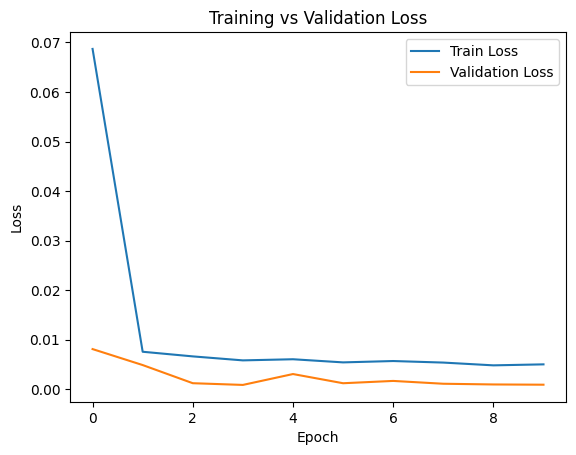

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()

#GRAFIK PERBANDINGAN

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

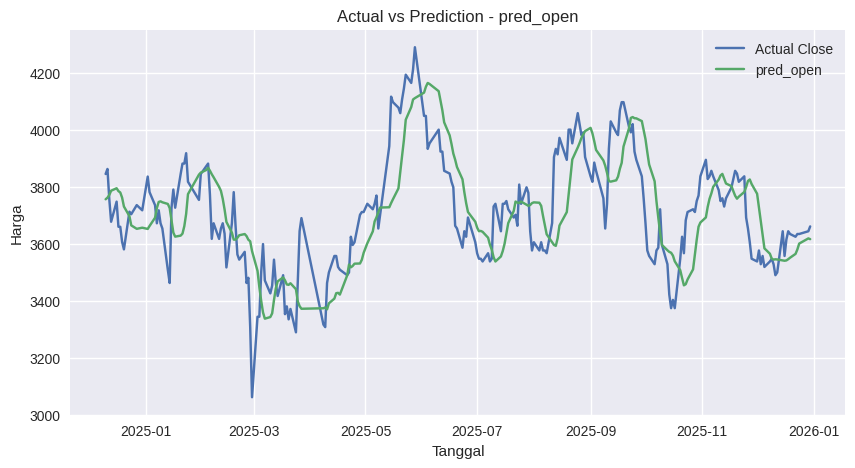

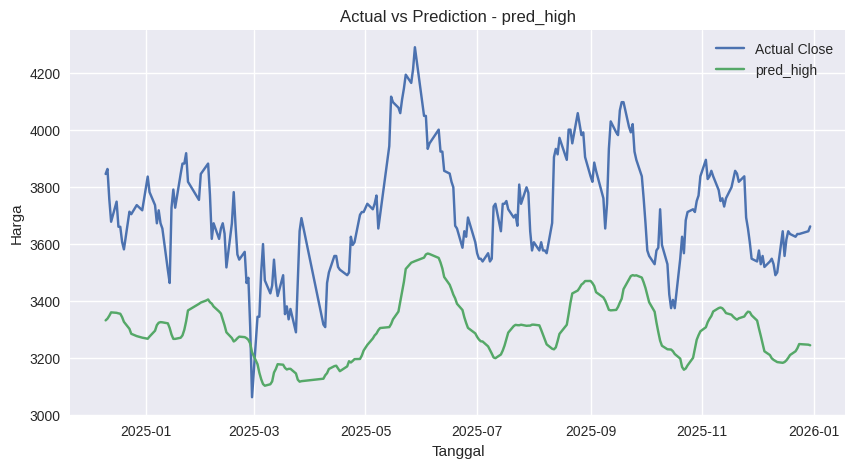

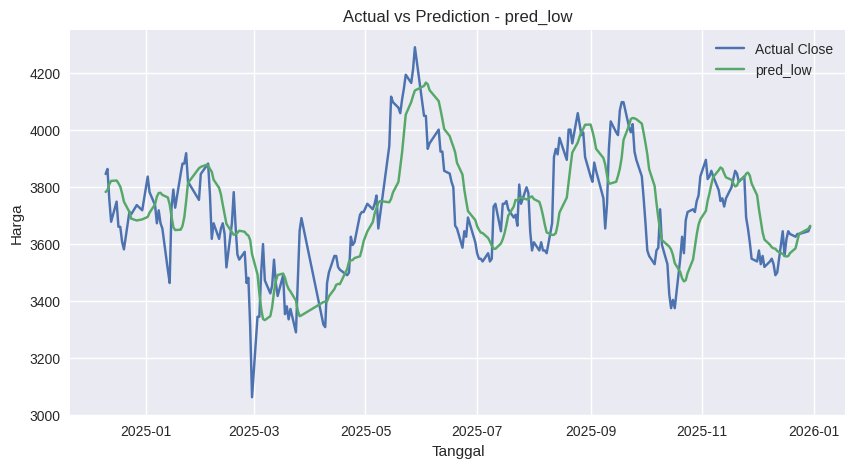

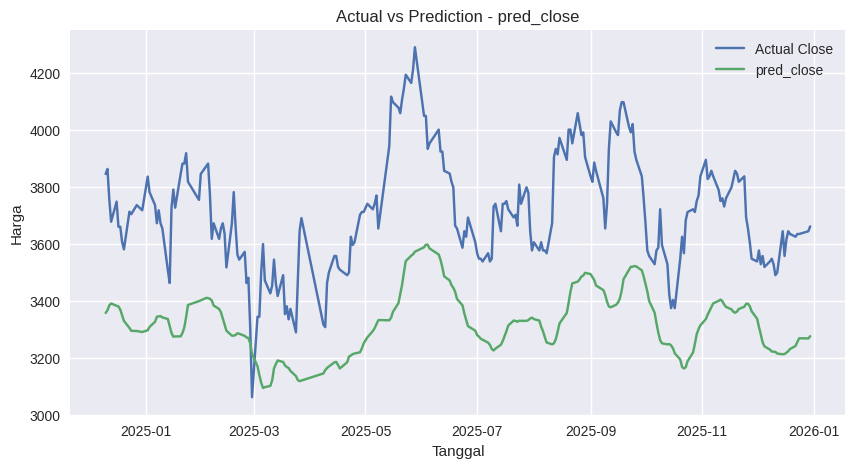

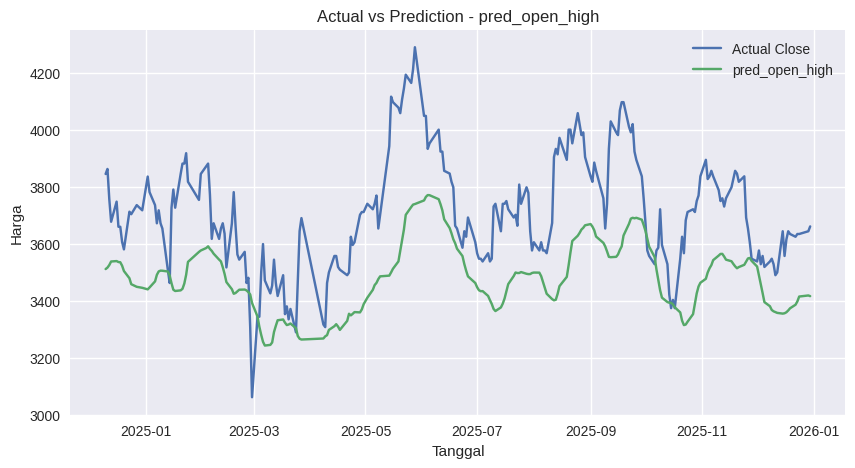

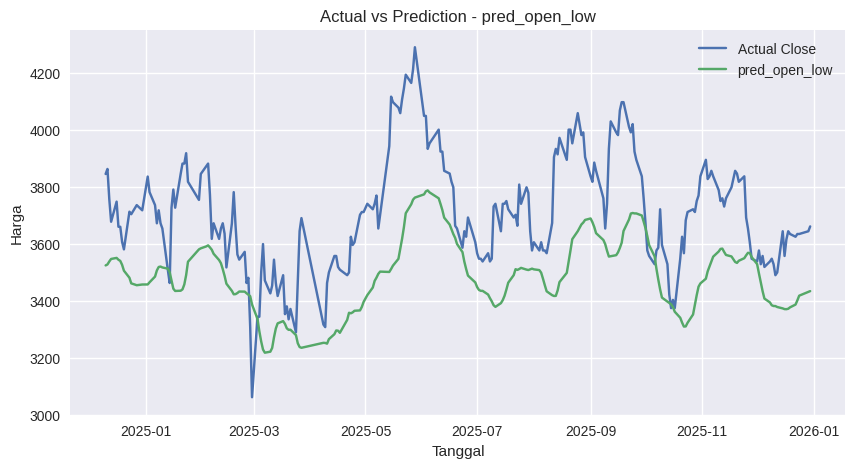

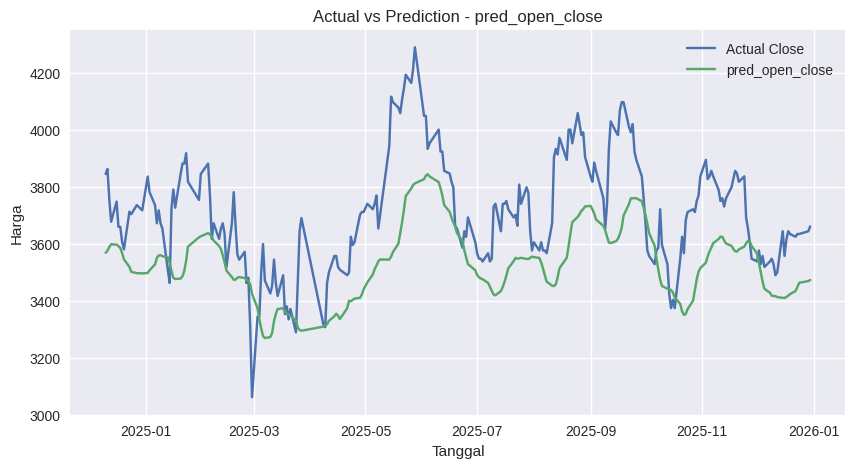

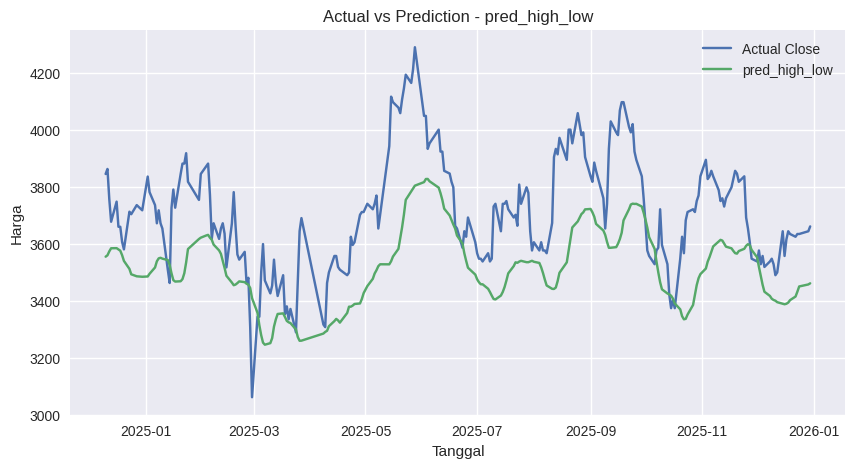

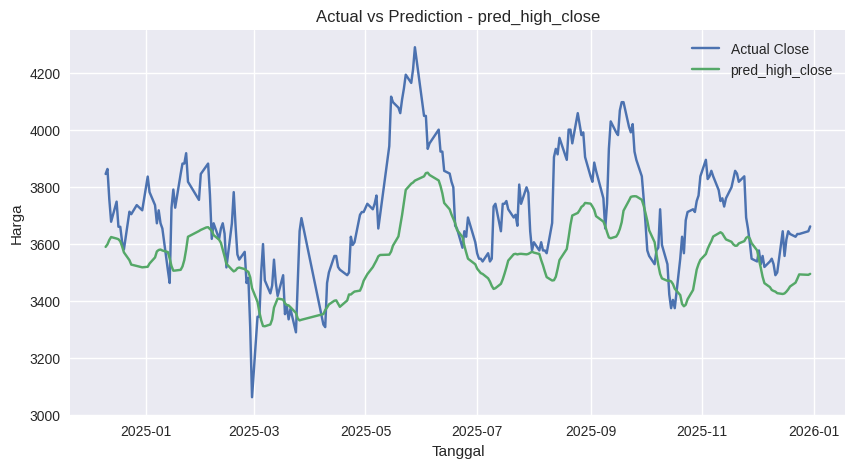

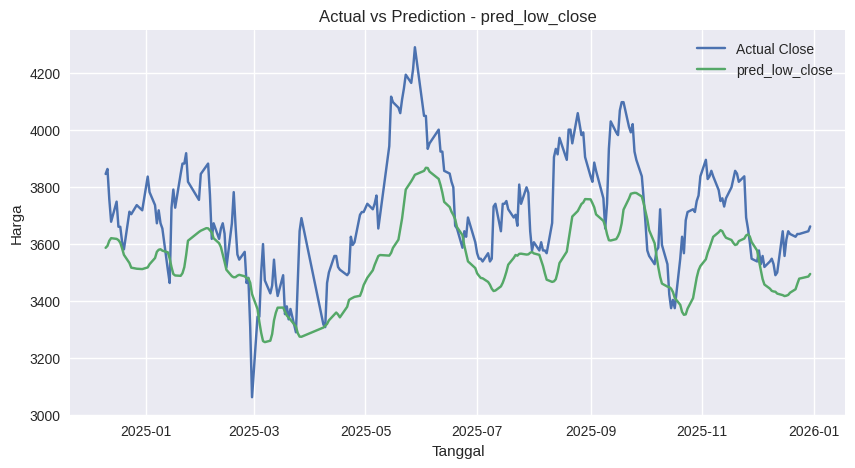

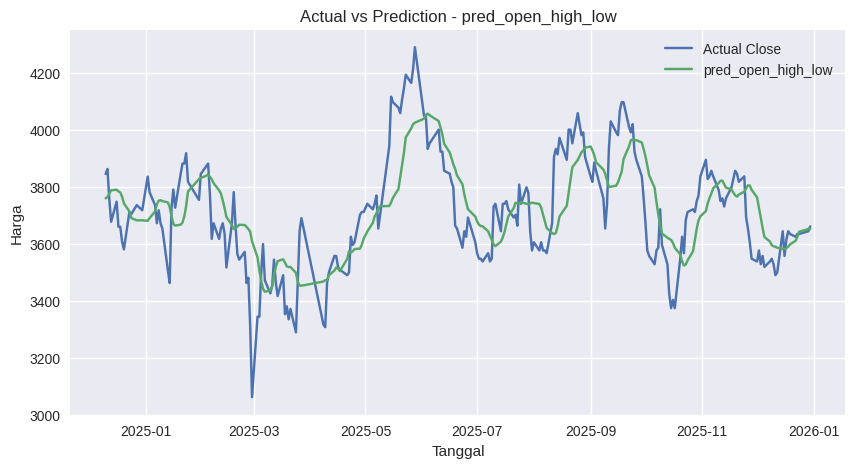

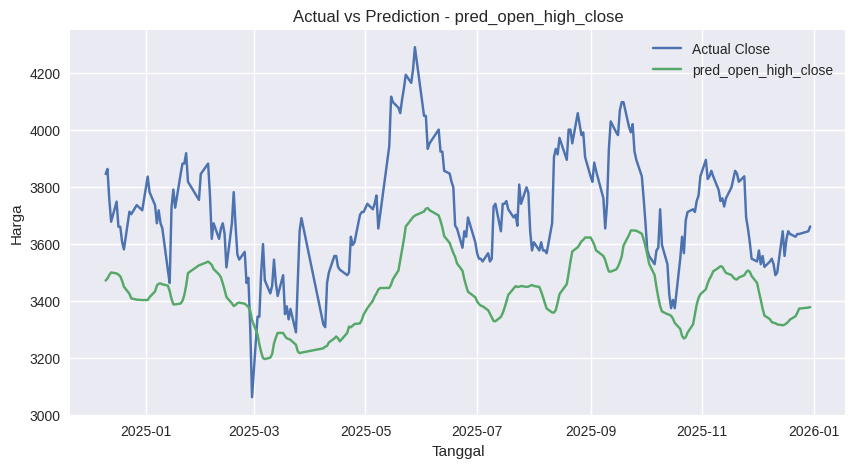

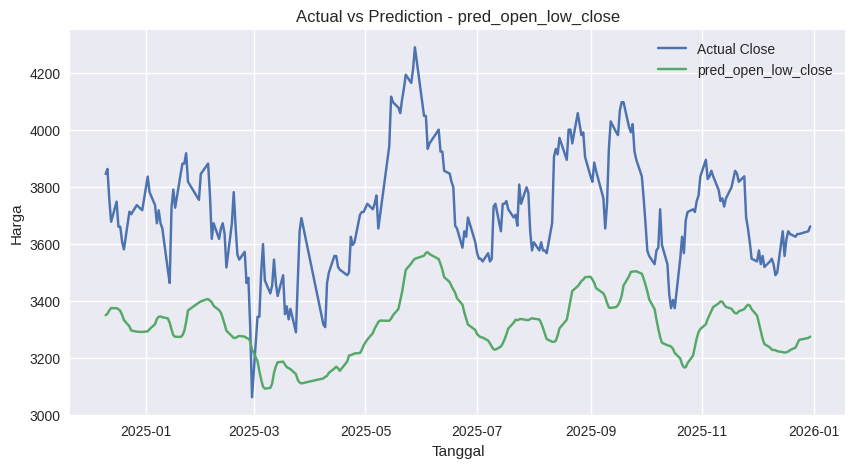

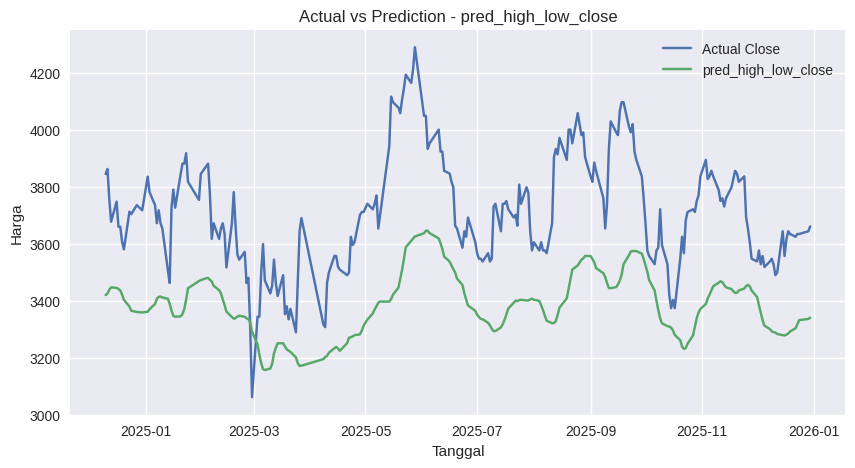

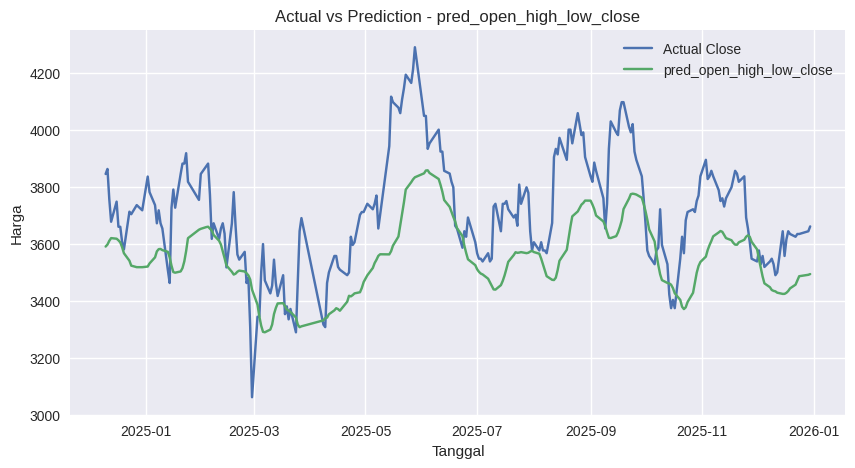

In [ ]:
import matplotlib.pyplot as plt

for col in prediction_columns:
    plt.style.use("seaborn-v0_8")
    plt.figure(figsize=(10,5))

    plt.plot(results_df["date"], results_df["actual_close"], label="Actual Close")
    plt.plot(results_df["date"], results_df[col], label=col)

    plt.title(f"Actual vs Prediction - {col}")
    plt.xlabel("Tanggal")
    plt.ylabel("Harga")

    plt.legend()
    plt.grid(True)

    plt.show()

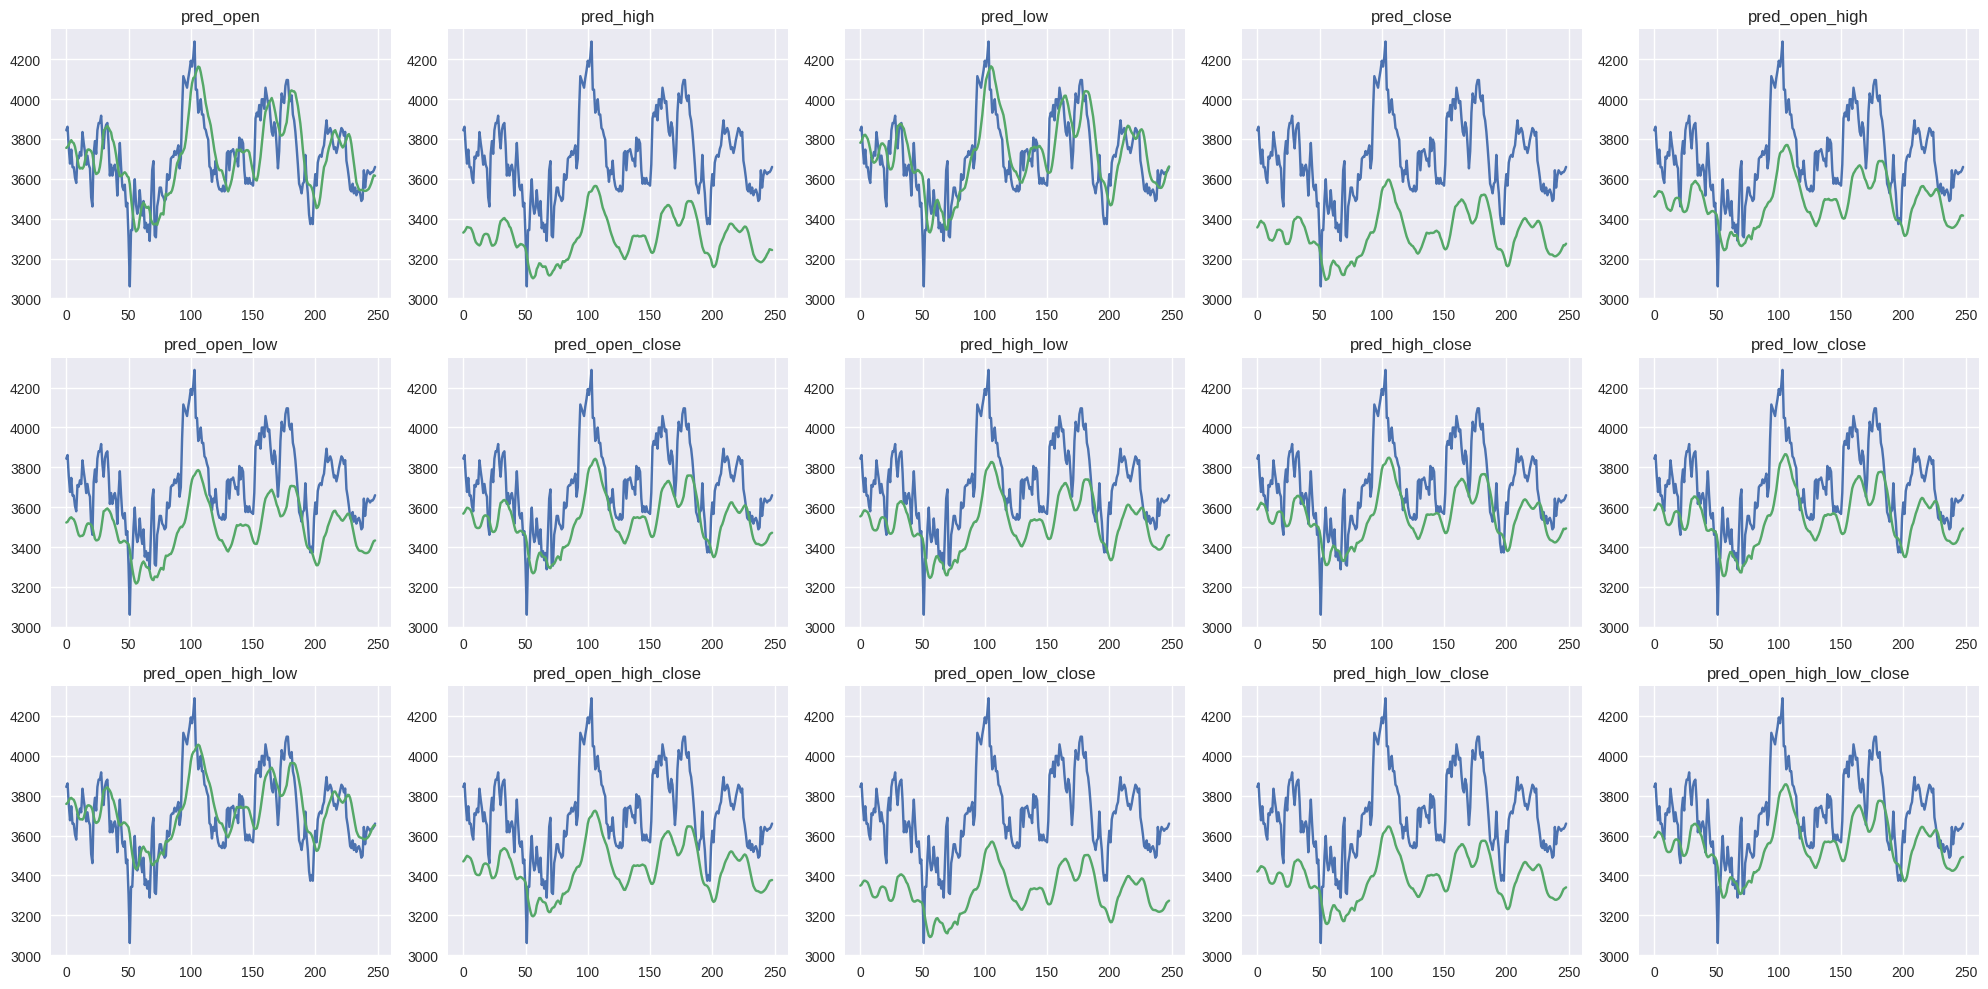

In [ ]:
fig, axes = plt.subplots(3,5, figsize=(20,10))
axes = axes.flatten()

for i, col in enumerate(prediction_columns):

    axes[i].plot(results_df["actual_close"], label="Actual")
    axes[i].plot(results_df[col], label="Prediksi")

    axes[i].set_title(col)
    axes[i].grid(True)

plt.style.use("seaborn-v0_8")
plt.tight_layout()
plt.show()

# MSE without DIFFERENCING

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

In [ ]:
import numpy as np
import pandas as pd

# Error setiap model
for col in prediction_columns:

    error_col = "error_" + col

    results_df[error_col] = (results_df["actual_close"] - results_df[col])**2


# MSE dan RMSE setiap model
evaluation_results = []

for col in prediction_columns:

    error_col = "error_" + col

    mse = results_df[error_col].mean()
    rmse = np.sqrt(mse)

    evaluation_results.append([col, mse, rmse])


# Membuat tabel evaluasi
tabel_evaluasi = pd.DataFrame(evaluation_results, columns=["Model", "MSE", "RMSE"])

print(tabel_evaluasi)

                       Model            MSE        RMSE
0                  pred_open   21941.334443  148.126076
1                  pred_high  183043.329963  427.835634
2                   pred_low   20194.659859  142.107916
3                 pred_close  167748.857632  409.571554
4             pred_open_high   71874.454904  268.094116
5              pred_open_low   68970.207661  262.621796
6            pred_open_close   50231.129886  224.123024
7              pred_high_low   55866.559088  236.361078
8            pred_high_close   42575.012519  206.337133
9             pred_low_close   45755.946645  213.906397
10        pred_open_high_low   19348.882189  139.100259
11      pred_open_high_close   93295.190382  305.442614
12       pred_open_low_close  172903.060544  415.816138
13       pred_high_low_close  123281.768553  351.115036
14  pred_open_high_low_close   43122.424475  207.659395


In [ ]:
# Urutan model terbaik berdasarkan MSE

tabel_evaluasi = tabel_evaluasi.sort_values(by="MSE")
print(tabel_evaluasi)

                       Model            MSE        RMSE
10        pred_open_high_low   19348.882189  139.100259
2                   pred_low   20194.659859  142.107916
0                  pred_open   21941.334443  148.126076
8            pred_high_close   42575.012519  206.337133
14  pred_open_high_low_close   43122.424475  207.659395
9             pred_low_close   45755.946645  213.906397
6            pred_open_close   50231.129886  224.123024
7              pred_high_low   55866.559088  236.361078
5              pred_open_low   68970.207661  262.621796
4             pred_open_high   71874.454904  268.094116
11      pred_open_high_close   93295.190382  305.442614
13       pred_high_low_close  123281.768553  351.115036
3                 pred_close  167748.857632  409.571554
12       pred_open_low_close  172903.060544  415.816138
1                  pred_high  183043.329963  427.835634


# PREDIKSI 7 HARI KE DEPAN

In [ ]:
last_sequence = X_test_open[-1]
last_sequence

array([[0.74436287],
       [0.7584079 ],
       [0.76994153],
       [0.76303968],
       [0.7607269 ],
       [0.76303971],
       [0.76534637]])

In [ ]:
future_predictions = []

current_sequence = last_sequence.copy()

for i in range(8):

    pred = models["open"].predict(current_sequence.reshape(1, current_sequence.shape[0], current_sequence.shape[1]))

    future_predictions.append(pred[0,0])

    # update window
    current_sequence = np.roll(current_sequence, -1, axis=0)

    # masukkan prediksi ke timestep terakhir
    current_sequence[-1, 0] = pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


/tmp/ipykernel_6000/3722611659.py:15: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  current_sequence[-1, 0] = pred


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


In [ ]:
future_predictions = np.array(future_predictions).reshape(-1,1)

# inverse scaler
future_log = scaler_close.inverse_transform(future_predictions)

# inverse log
future_prices = np.exp(future_log)

future_prices = future_prices.flatten()

In [ ]:
print("Prediksi harga saham 7 hari ke depan:")

for i, price in enumerate(future_prices, start=1):
    print(f"Hari ke-{i}: {price:.2f}")

Prediksi harga saham 7 hari ke depan:
Hari ke-1: 3615.25
Hari ke-2: 3628.43
Hari ke-3: 3633.51
Hari ke-4: 3633.02
Hari ke-5: 3637.87
Hari ke-6: 3644.75
Hari ke-7: 3650.77
Hari ke-8: 3656.08
